# CART Regression: House Price Prediction

**Objective:** predict a continuous house price from property characteristics using CART (Classification and Regression Trees). Compare an unrestricted tree with pre-pruned and cost-complexity post-pruned trees, selecting the final model using training-only cross-validation.

**Workflow:** generate and inspect data → reserve a test set → train and tune trees → select by cross-validation → evaluate held-out predictions → interpret the model → predict a new house.

CART uses binary threshold splits. With the squared-error criterion, each leaf predicts the **mean training target** in that leaf. Unlike classification, which predicts class labels and reduces class impurity, this regression tree reduces squared prediction error.

We generate 400 synthetic house prices in **lakhs of rupees** with a fixed random seed. These are educational data, not actual property transactions; results measure recovery of the simulated relationships and do not establish real-world valuation accuracy. All features are numeric, so categorical encoding and feature scaling are unnecessary.

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.tree import DecisionTreeRegressor, plot_tree, export_text
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
plt.rcParams['figure.figsize'] = (10, 5)

## 1. Generate and inspect the regression dataset

The simulation gives larger houses and additional bedrooms higher prices, while age and distance reduce prices. Houses within 5 km receive an additional premium. Gaussian noise represents unexplained variation. Prices are clipped at 10 lakhs and rounded to two decimals.

| Variable | Meaning | Unit |
|---|---|---|
| Area_sqft | Floor area | square feet |
| Bedrooms | Number of bedrooms | count |
| Age_years | Property age | years |
| Distance_km | Distance from the assumed city center | km |
| Price_lakhs | Prediction target | lakhs of rupees |

These features are generated independently for simplicity. Real housing data can have correlations, location effects, missing values, and changing market conditions that this exercise does not model.

In [28]:
rng = np.random.default_rng(RANDOM_STATE)
n = 400

df = pd.DataFrame({
    'Area_sqft': rng.integers(600, 3501, n),
    'Bedrooms': rng.integers(1, 6, n),
    'Age_years': rng.integers(0, 31, n),
    'Distance_km': rng.uniform(1, 25, n).round(1),
})
df['Price_lakhs'] = (
    15 + 0.035 * df['Area_sqft'] + 4 * df['Bedrooms']
    - 0.6 * df['Age_years'] - 1.2 * df['Distance_km']
    + 15 * (df['Distance_km'] <= 5)
    + rng.normal(0, 5, n)
).clip(lower=10).round(2)

print('Dataset shape:', df.shape)
display(df.head(10))
display(df.describe().round(2))
assert not df.isna().any().any()

Dataset shape: (400, 5)


,Area_sqft,Bedrooms,Age_years,Distance_km,Price_lakhs
0,858,5,0,12.5,46.32
1,2845,4,9,19.3,106.64
2,2498,2,15,22.7,74.36
3,1873,5,28,18.3,60.38
4,1856,3,22,24.1,49.31
5,3090,3,24,19.8,98.11
6,849,3,16,21.8,24.04
7,2623,1,3,3.7,114.57
8,1184,5,12,18.6,41.71
9,873,1,30,11.6,23.16


,Area_sqft,Bedrooms,Age_years,Distance_km,Price_lakhs
count,400.00,400.00,400.00,400.00,400.00
mean,2040.36,3.07,14.96,12.98,76.89
std,818.89,1.44,8.95,7.16,32.64
min,615.00,1.00,0.00,1.00,10.00
25%,1363.25,2.00,7.00,6.80,51.54
50%,2017.00,3.00,15.00,12.80,76.73
75%,2761.50,4.00,23.00,19.42,100.28
max,3489.00,5.00,30.00,25.00,152.84


## 2. Separate features and target, then split the data

Reserve 25% (100 rows) for testing and use the remaining 300 rows for training and model selection. A fixed random seed makes the experiment reproducible. No test observations are used to fit or tune a model.

Five shuffled cross-validation folds estimate validation error within the training set. All candidates use the same folds. We optimize mean fold **MSE** and report its square root as **CV RMSE**; this is the square root of mean fold MSE, not the arithmetic mean of fold RMSEs.

In [29]:
X = df.drop(columns='Price_lakhs')
y = df['Price_lakhs']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE
)
print('Training rows:', len(X_train))
print('Testing rows:', len(X_test))
print('Features:', X.columns.tolist())
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
assert set(X_train.index).isdisjoint(X_test.index)
assert list(X_train.columns) == list(X_test.columns)

Training rows: 300
Testing rows: 100
Features: ['Area_sqft', 'Bedrooms', 'Age_years', 'Distance_km']


## 3. Train the full CART regression tree

For a node containing $n$ observations, squared-error impurity is $\frac{1}{n}\sum_i(y_i-\bar{y})^2$. CART chooses a feature and threshold that reduce the sample-weighted child impurity. Predictions are constant within each leaf.

An unrestricted tree can create one leaf per training observation, giving zero training error. Its cross-validation error is a better indication of generalization than its training score. In tree diagrams, `value` is the predicted mean price, `samples` is the training count, and `squared_error` is the node's target variance.

In [30]:
full_tree = DecisionTreeRegressor(criterion='squared_error', random_state=RANDOM_STATE)
full_tree.fit(X_train, y_train)
print('Tree depth:', full_tree.get_depth())
print('Number of leaves:', full_tree.get_n_leaves())
print('Training R²:', round(full_tree.score(X_train, y_train), 3))
full_cv_mse = -cross_val_score(full_tree, X_train, y_train, scoring='neg_mean_squared_error', cv=cv)
print('Full-tree CV RMSE:', round(np.sqrt(full_cv_mse.mean()), 2), 'lakhs')

Tree depth: 14
Number of leaves: 300
Training R²: 1.0
Full-tree CV RMSE: 11.46 lakhs


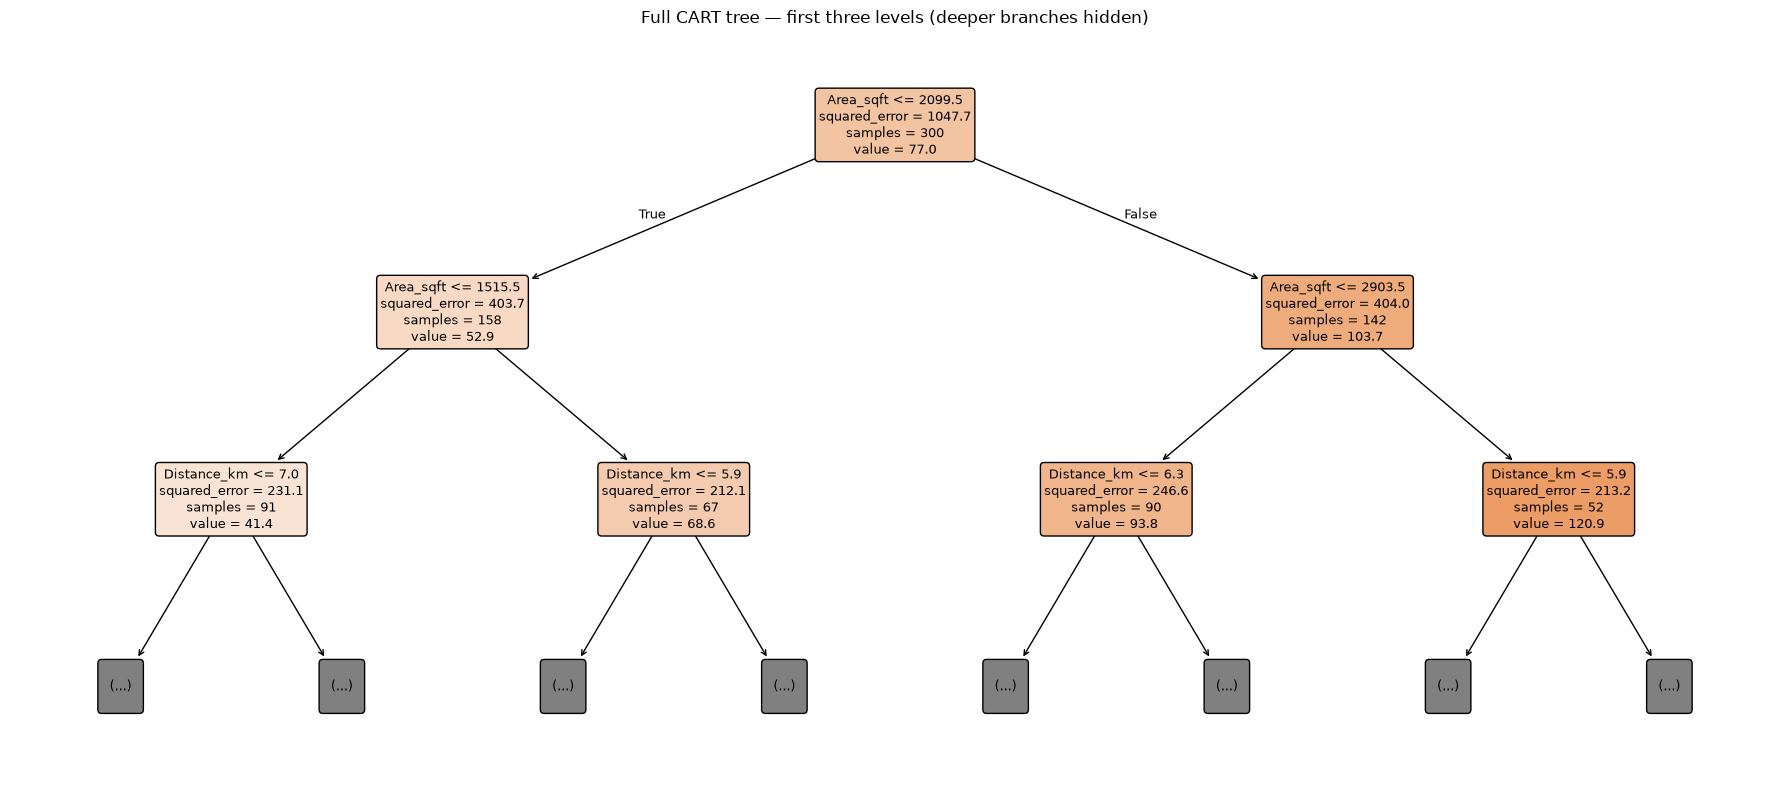

In [31]:
plt.figure(figsize=(18, 8))
plot_tree(full_tree, feature_names=X.columns.tolist(), filled=True,
          rounded=True, max_depth=2, precision=1, fontsize=9)
plt.title('Full CART tree — first three levels (deeper branches hidden)')
plt.tight_layout()
plt.show()

## 4. Pre-pruning: restrict tree growth

Tune maximum depth and minimum samples per leaf using five-fold training-only cross-validation. A shallow tree may underfit; very small leaves can fit noise. The grid includes unrestricted depth so validation can determine whether a depth limit helps when a minimum leaf size is enforced.

Grid search refits the chosen candidate on all training rows. Scores used for tuning can be optimistic because multiple candidates were compared; the held-out test set provides a separate evaluation.

In [32]:
pre_search = GridSearchCV(
    DecisionTreeRegressor(random_state=RANDOM_STATE),
    param_grid={'max_depth': [2, 3, 4, 5, 6, 8, 10, None], 'min_samples_leaf': [2, 5, 10]},
    scoring='neg_mean_squared_error', cv=cv, error_score='raise'
)
pre_search.fit(X_train, y_train)
pruned_tree = pre_search.best_estimator_
print('Best pre-pruning parameters:', pre_search.best_params_)
print('Cross-validation RMSE:', round(np.sqrt(-pre_search.best_score_), 2))
print('Depth:', pruned_tree.get_depth(), '| Leaves:', pruned_tree.get_n_leaves())
pre_results = pd.DataFrame(pre_search.cv_results_)
pre_results['CV RMSE'] = np.sqrt(-pre_results['mean_test_score'])
display(pre_results[['param_max_depth', 'param_min_samples_leaf', 'CV RMSE']]
        .sort_values('CV RMSE').head(8).round(3))

Best pre-pruning parameters: {'max_depth': 10, 'min_samples_leaf': 5}
Cross-validation RMSE: 10.82
Depth: 9 | Leaves: 48


,param_max_depth,param_min_samples_leaf,CV RMSE
19,10,5,10.819
22,None,5,10.819
16,8,5,10.822
13,6,5,10.945
18,10,2,11.136
21,None,2,11.198
15,8,2,11.330
10,5,5,11.372


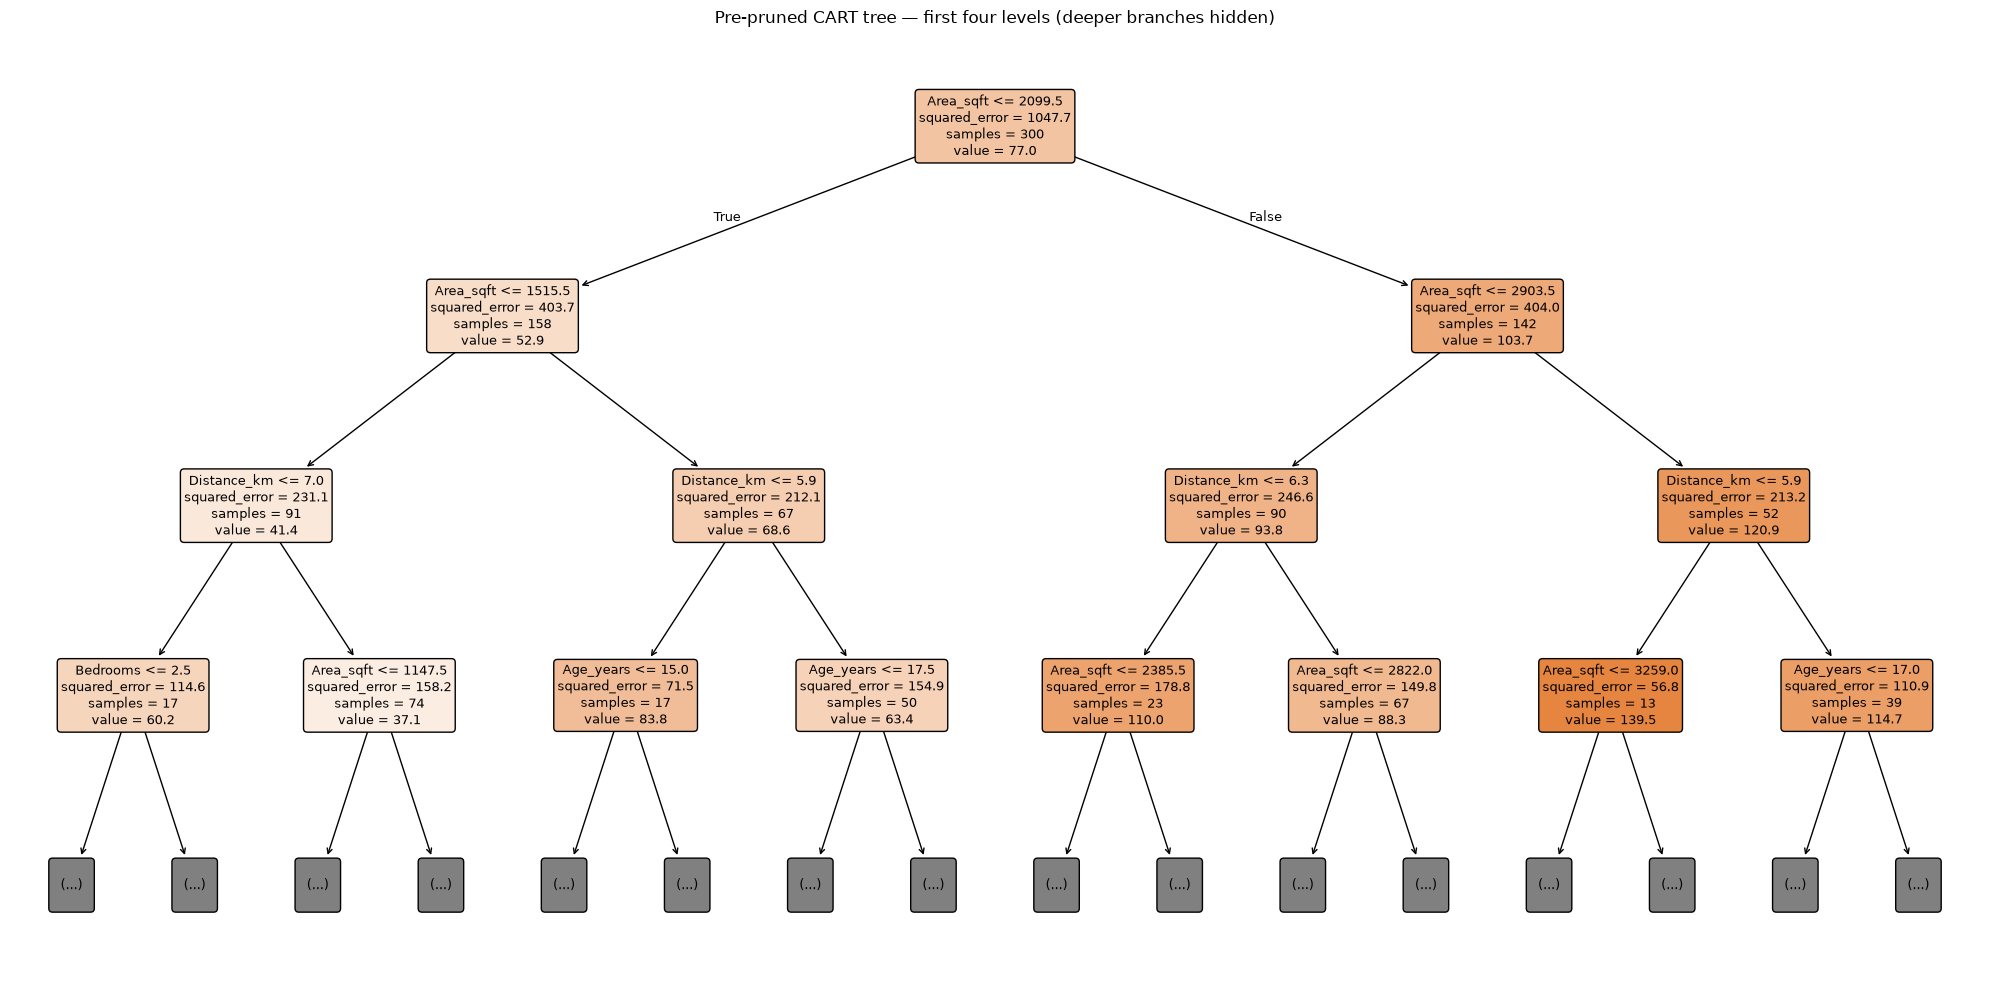

In [33]:
plt.figure(figsize=(20, 10))
plot_tree(pruned_tree, feature_names=X.columns.tolist(), filled=True,
          rounded=True, max_depth=3, precision=1, fontsize=9)
plt.title('Pre-pruned CART tree — first four levels (deeper branches hidden)')
plt.tight_layout()
plt.show()

## 5. Post-pruning: cost-complexity pruning

Cost-complexity pruning balances total weighted leaf impurity against `ccp_alpha × number of leaves`. Increasing alpha favors smaller trees; alpha 0 allows the unrestricted tree. The full-training pruning path illustrates how impurity changes with alpha.

Search a fixed alpha grid with training-only cross-validation so validation-fold targets do not define the candidate grid. Select the alpha with the lowest mean fold MSE. Pruning is not guaranteed to improve test accuracy, and alpha 0 is a valid outcome.

First ten pruning-path alphas: [0.     0.     0.     0.     0.     0.     0.0001 0.0001 0.0001 0.0001]
Selected alpha: 0.3455
Cross-validation RMSE: 11.32
Depth: 11 | Leaves: 76


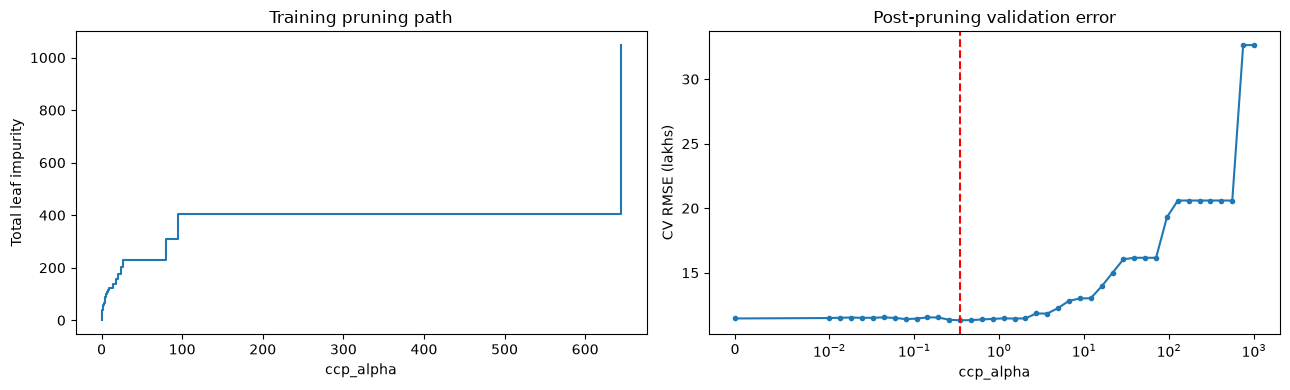

In [34]:
path = full_tree.cost_complexity_pruning_path(X_train, y_train)
print('First ten pruning-path alphas:', np.round(path.ccp_alphas[:10], 4))

alpha_grid = np.r_[0.0, np.logspace(-2, 3, 40)]
post_search = GridSearchCV(
    DecisionTreeRegressor(random_state=RANDOM_STATE),
    param_grid={'ccp_alpha': alpha_grid},
    scoring='neg_mean_squared_error', cv=cv, error_score='raise'
)
post_search.fit(X_train, y_train)
post_pruned_tree = post_search.best_estimator_
print('Selected alpha:', round(post_search.best_params_['ccp_alpha'], 4))
print('Cross-validation RMSE:', round(np.sqrt(-post_search.best_score_), 2))
print('Depth:', post_pruned_tree.get_depth(), '| Leaves:', post_pruned_tree.get_n_leaves())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].step(path.ccp_alphas, path.impurities, where='post')
axes[0].set(xlabel='ccp_alpha', ylabel='Total leaf impurity', title='Training pruning path')
axes[1].plot(alpha_grid, np.sqrt(-post_search.cv_results_['mean_test_score']), marker='.')
axes[1].set_xscale('symlog', linthresh=0.01)
axes[1].axvline(post_search.best_params_['ccp_alpha'], color='red', linestyle='--')
axes[1].set(xlabel='ccp_alpha', ylabel='CV RMSE (lakhs)', title='Post-pruning validation error')
plt.tight_layout()
plt.show()

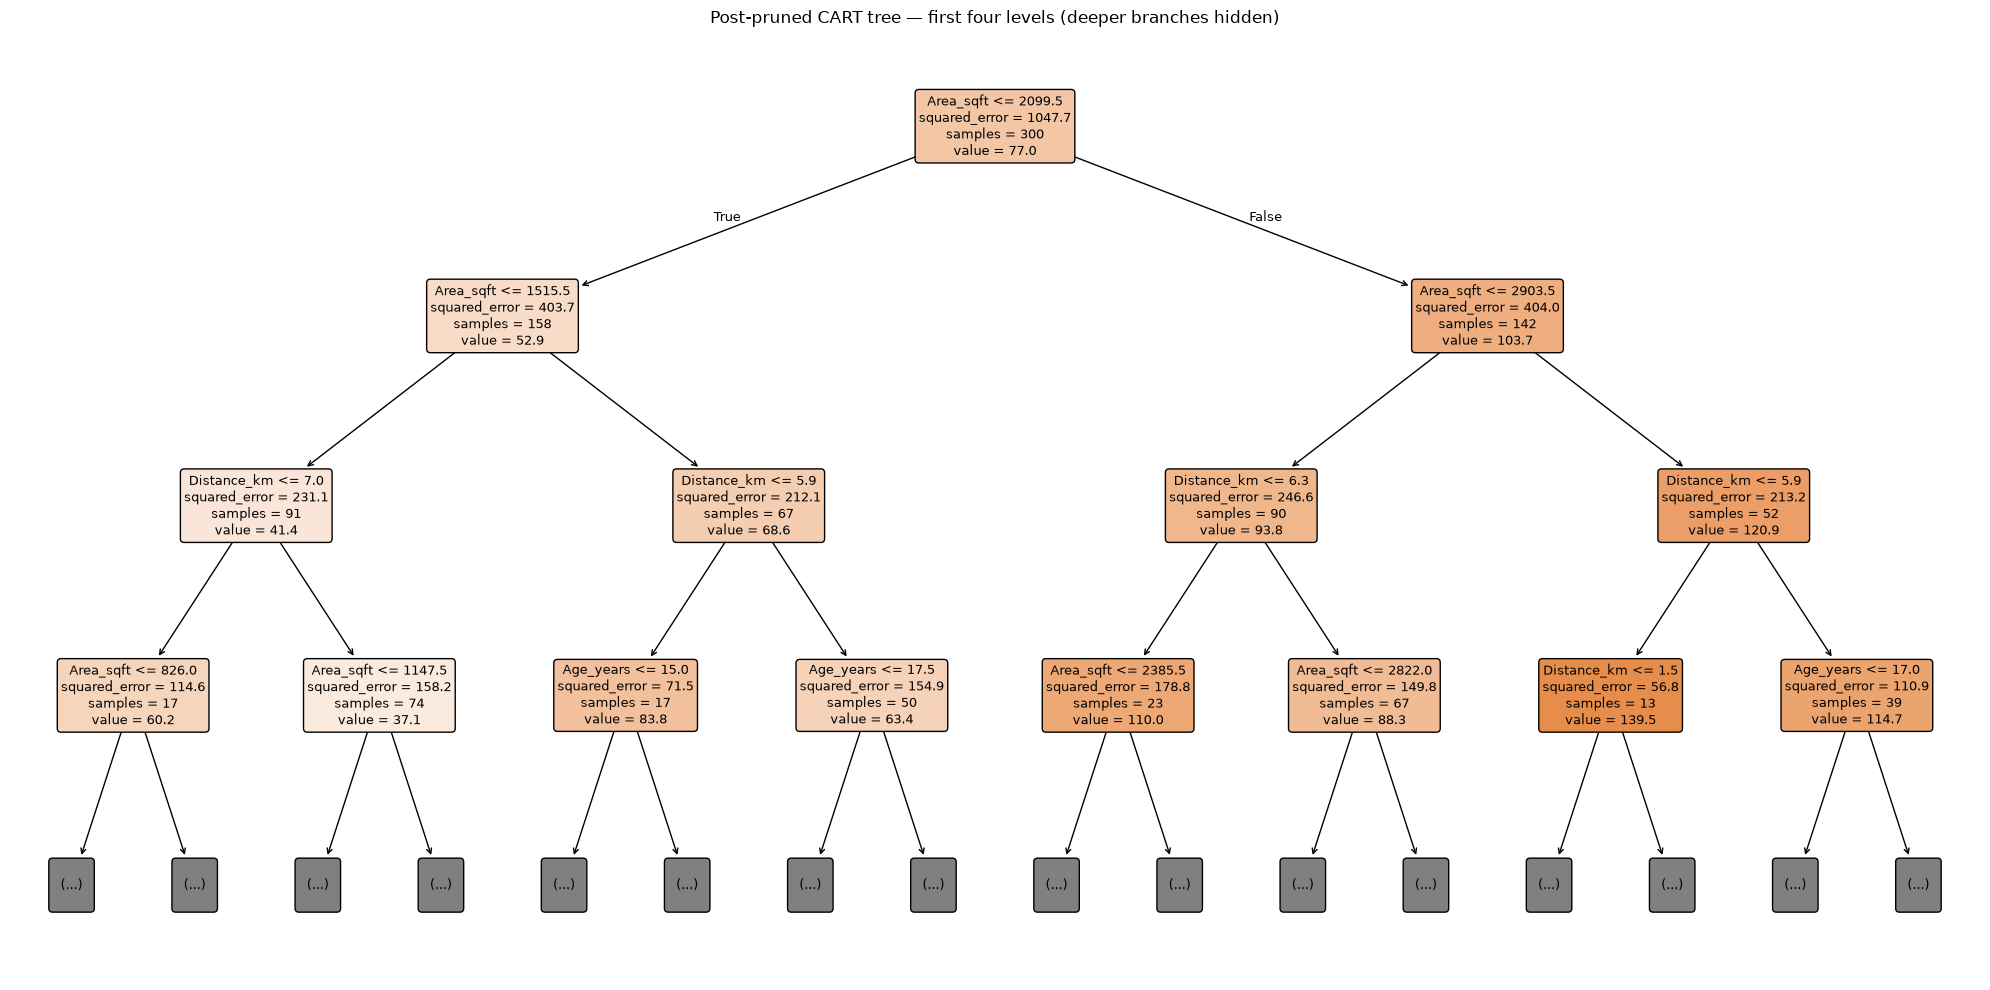

In [35]:
plt.figure(figsize=(20, 10))
plot_tree(post_pruned_tree, feature_names=X.columns.tolist(), filled=True,
          rounded=True, max_depth=3, precision=1, fontsize=9)
plt.title('Post-pruned CART tree — first four levels (deeper branches hidden)')
plt.tight_layout()
plt.show()

## 6. Select by cross-validation, then evaluate on held-out data

Compare the full tree with the best pre-pruned and post-pruned candidates using training CV MSE. Exact ties favor fewer leaves and then lower depth. Freeze this choice before reporting test metrics; do not replace it with whichever model happens to rank first on this test split.

**MAE** is average absolute error; **RMSE** gives larger errors more weight. Both are in lakhs and lower is better. **R²** compares squared error with a constant test-mean reference: higher is better, 1 is perfect, and values can be negative. A baseline fitted to the training mean shows whether the trees learn useful patterns.

Model selected by training cross-validation: Pre-Pruned Tree


,Depth,Leaves,CV RMSE,Train RMSE,Test MAE,Test RMSE,Test R2
Model,,,,,,,
Mean baseline,NaN,NaN,32.636,32.369,28.344,33.289,-0.000
Full Tree,14.0,300.0,11.462,0.000,9.042,11.438,0.882
Pre-Pruned Tree,9.0,48.0,10.819,6.072,9.775,12.563,0.858
Post-Pruned Tree,11.0,76.0,11.320,3.748,9.918,12.013,0.870


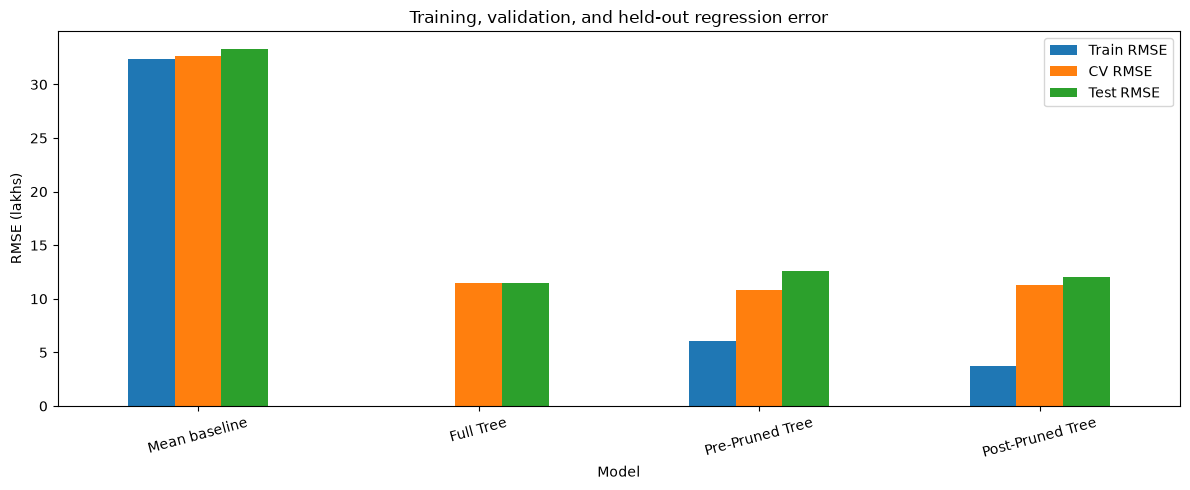

In [36]:
baseline = DummyRegressor(strategy='mean').fit(X_train, y_train)
baseline_cv_mse = -cross_val_score(baseline, X_train, y_train, scoring='neg_mean_squared_error', cv=cv)
models = {'Mean baseline': baseline, 'Full Tree': full_tree,
          'Pre-Pruned Tree': pruned_tree, 'Post-Pruned Tree': post_pruned_tree}
cv_mse = {'Mean baseline': baseline_cv_mse.mean(), 'Full Tree': full_cv_mse.mean(),
          'Pre-Pruned Tree': -pre_search.best_score_, 'Post-Pruned Tree': -post_search.best_score_}
best_model_name = min(
    ['Full Tree', 'Pre-Pruned Tree', 'Post-Pruned Tree'],
    key=lambda name: (cv_mse[name], models[name].get_n_leaves(), models[name].get_depth())
)
best_model = models[best_model_name]
print('Model selected by training cross-validation:', best_model_name)

rows = []
for name, model in models.items():
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    rows.append({
        'Model': name,
        'Depth': model.get_depth() if hasattr(model, 'get_depth') else np.nan,
        'Leaves': model.get_n_leaves() if hasattr(model, 'get_n_leaves') else np.nan,
        'CV RMSE': np.sqrt(cv_mse[name]),
        'Train RMSE': np.sqrt(mean_squared_error(y_train, train_pred)),
        'Test MAE': mean_absolute_error(y_test, test_pred),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, test_pred)),
        'Test R2': r2_score(y_test, test_pred),
    })
comparison = pd.DataFrame(rows).set_index('Model')
display(comparison.round(3))
comparison[['Train RMSE', 'CV RMSE', 'Test RMSE']].plot.bar(
    figsize=(12, 5), rot=15, title='Training, validation, and held-out regression error'
)
plt.ylabel('RMSE (lakhs)')
plt.tight_layout()
plt.show()

## 7. Inspect predictions, residuals, and feature importance

Residual = actual price minus predicted price: positive residuals mean underprediction. Predictions near the diagonal in the first plot are accurate. A residual plot centered around zero without a strong pattern is desirable; structured patterns can reveal relationships the tree misses.

Impurity importance sums the weighted error reductions attributable to each feature. It describes this fitted tree, can favor features with more possible splits, and does not establish causation.

,Area_sqft,Bedrooms,Age_years,Distance_km,Actual_price,Predicted_price,Residual
209,2859,5,16,24.8,91.90,109.75,-17.85
280,1400,4,28,10.8,41.20,54.19,-12.99
33,2208,1,4,9.9,81.70,81.83,-0.13
210,1357,5,8,1.1,92.12,68.48,23.64
93,1724,4,30,8.8,62.01,65.17,-3.16
84,2426,3,25,16.2,76.45,75.08,1.37
329,2209,4,20,18.6,66.12,90.72,-24.60
94,3205,2,23,22.8,101.29,98.28,3.02
266,1896,3,28,21.8,50.83,48.57,2.26
126,829,5,16,6.9,47.04,61.69,-14.65


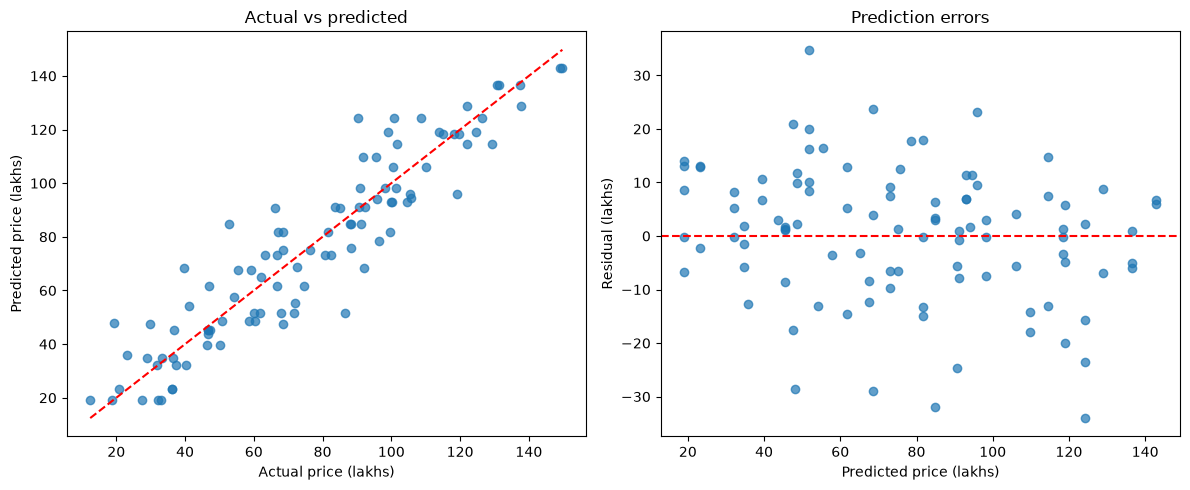

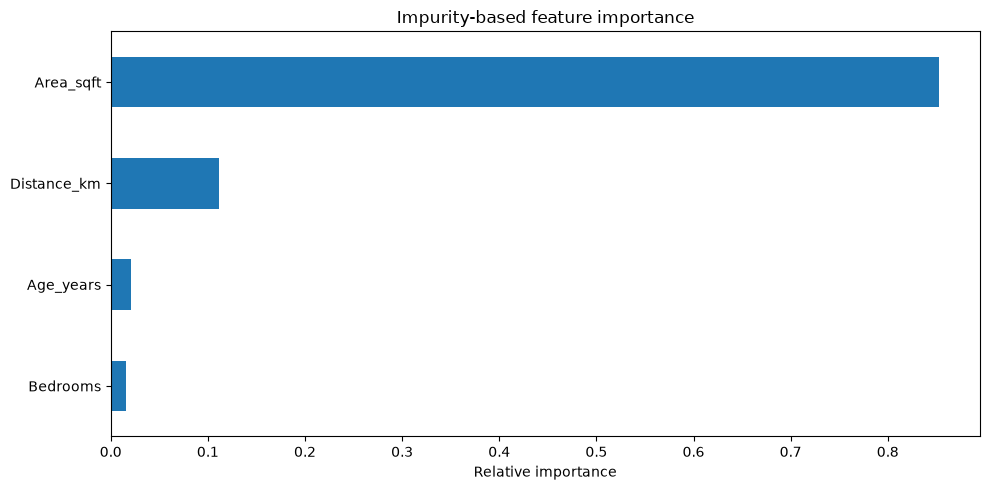

In [37]:
predictions = best_model.predict(X_test)
results = X_test.copy()
results['Actual_price'] = y_test
results['Predicted_price'] = predictions
results['Residual'] = results['Actual_price'] - results['Predicted_price']
display(results.head(10).round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(y_test, predictions, alpha=0.7)
limits = [min(y_test.min(), predictions.min()), max(y_test.max(), predictions.max())]
axes[0].plot(limits, limits, 'r--')
axes[0].set(xlabel='Actual price (lakhs)', ylabel='Predicted price (lakhs)', title='Actual vs predicted')
axes[1].scatter(predictions, y_test - predictions, alpha=0.7)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set(xlabel='Predicted price (lakhs)', ylabel='Residual (lakhs)', title='Prediction errors')
plt.tight_layout()
plt.show()

importance = pd.Series(best_model.feature_importances_, index=X.columns).sort_values()
importance.plot.barh(title='Impurity-based feature importance')
plt.xlabel('Relative importance')
plt.tight_layout()
plt.show()

## 8. Predict a new house and explain the prediction

Supply feature values in the same units and column order as training. This hypothetical house has no observed target, so its prediction is a demonstration rather than an accuracy check. The tree predicts the mean price of training houses in the reached leaf; it cannot smoothly extrapolate outside the training target range.

The tree rules below include the full selected model, even though the diagrams hide deeper branches for readability.

In [38]:
new_house = pd.DataFrame({
    'Area_sqft': [1800], 'Bedrooms': [3], 'Age_years': [5], 'Distance_km': [8.0]
})
display(new_house)
print(f'Predicted house price: {best_model.predict(new_house)[0]:.2f} lakhs')
print('Selected tree rules:')
print(export_text(best_model, feature_names=X.columns.tolist(), decimals=2))
leaf_id = best_model.apply(new_house)[0]
training_leaf_ids = best_model.apply(X_train)
leaf_targets = y_train.loc[training_leaf_ids == leaf_id]
print('Training houses in the reached leaf:', len(leaf_targets))
print(f'Mean training price in this leaf: {leaf_targets.mean():.2f} lakhs')
assert np.isclose(best_model.predict(new_house)[0], leaf_targets.mean())

,Area_sqft,Bedrooms,Age_years,Distance_km
0,1800,3,5,8.0


Predicted house price: 67.58 lakhs
Selected tree rules:
|--- Area_sqft <= 2099.50
|   |--- Area_sqft <= 1515.50
|   |   |--- Distance_km <= 6.95
|   |   |   |--- Bedrooms <= 2.50
|   |   |   |   |--- value: [51.69]
|   |   |   |--- Bedrooms >  2.50
|   |   |   |   |--- Area_sqft <= 1118.00
|   |   |   |   |   |--- value: [61.69]
|   |   |   |   |--- Area_sqft >  1118.00
|   |   |   |   |   |--- value: [68.48]
|   |   |--- Distance_km >  6.95
|   |   |   |--- Area_sqft <= 1147.50
|   |   |   |   |--- Area_sqft <= 749.50
|   |   |   |   |   |--- value: [19.05]
|   |   |   |   |--- Area_sqft >  749.50
|   |   |   |   |   |--- Distance_km <= 21.70
|   |   |   |   |   |   |--- Age_years <= 12.50
|   |   |   |   |   |   |   |--- Distance_km <= 11.95
|   |   |   |   |   |   |   |   |--- value: [43.66]
|   |   |   |   |   |   |   |--- Distance_km >  11.95
|   |   |   |   |   |   |   |   |--- Bedrooms <= 3.50
|   |   |   |   |   |   |   |   |   |--- value: [34.76]
|   |   |   |   |   |   |   | 

## 9. Conclusions from this run

The summary below uses the executed results. A model selected by cross-validation can be outperformed by another model on a particular test split because validation and test samples differ. That is a reason to report both honestly, not to select again using the test set.

In [39]:
selected = comparison.loc[best_model_name]
test_leader = comparison['Test RMSE'].idxmin()
print('Selected model:', best_model_name)
print(f'Depth: {best_model.get_depth()} | Leaves: {best_model.get_n_leaves()}')
print(f'CV RMSE: {selected["CV RMSE"]:.2f} lakhs')
print(f'Test MAE: {selected["Test MAE"]:.2f} lakhs')
print(f'Test RMSE: {selected["Test RMSE"]:.2f} lakhs')
print(f'Test R²: {selected["Test R2"]:.3f}')
print(f'Average absolute error on these synthetic test houses: {selected["Test MAE"]:.2f} lakhs.')
print('Lowest test RMSE in the comparison:', test_leader)
if test_leader != best_model_name:
    print('The test ranking differs from cross-validation; we retain the CV-selected model.')
else:
    print('The selected model also has the lowest test RMSE in this comparison.')
improvement = 100 * (1 - selected['Test RMSE'] / comparison.loc['Mean baseline', 'Test RMSE'])
print(f'Test RMSE reduction relative to the mean baseline: {improvement:.1f}%')
assert len(predictions) == len(y_test)
assert np.isfinite(predictions).all()
assert best_model.n_features_in_ == X.shape[1]
print('Workflow checks passed.')

Selected model: Pre-Pruned Tree
Depth: 9 | Leaves: 48
CV RMSE: 10.82 lakhs
Test MAE: 9.77 lakhs
Test RMSE: 12.56 lakhs
Test R²: 0.858
Average absolute error on these synthetic test houses: 9.77 lakhs.
Lowest test RMSE in the comparison: Full Tree
The test ranking differs from cross-validation; we retain the CV-selected model.
Test RMSE reduction relative to the mean baseline: 62.3%
Workflow checks passed.


### Key takeaways and limitations

- The full tree can memorize training observations. Use validation and test errors to assess whether that fit generalizes.
- Pre-pruning restricts growth; post-pruning penalizes complexity. Neither guarantees a lower test error.
- All model selection in this final workflow uses training cross-validation. Test results are evaluation and interpretation only.
- This test split has already been inspected during notebook development, so it is not a completely untouched external benchmark. New independent data or nested cross-validation would support stronger performance claims.
- The data follow a deliberately constructed simulation. Results do not validate a model for actual property valuation; a real application requires representative data and appropriate validation.
- Tree predictions are constant within leaves and do not extrapolate smoothly. Feature importance is not causal evidence.
- The notebook is self-contained: run cells in order with NumPy, pandas, matplotlib, scikit-learn, and IPython installed. Dataset generation and model fitting use fixed random seeds; package versions can still affect numerical details.